In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
df = pd.read_csv('Skyrun dataset.csv', parse_dates=['InvoiceDate'])
df.head()

,InvoiceNo,InvoiceDate,CustomerID,StockCode,Description,Quantity,UnitPrice,Country
0,536365,2024-12-01 08:26:00,17850.0,SC1734,Electronics,65,10.23,Egypt
1,536365,2024-12-01 08:26:00,17850.0,SC2088,Furniture,95,19.61,Mali
2,536365,2024-12-01 08:26:00,17850.0,SC3463,Books,78,61.49,Mali
3,536365,2024-12-01 08:26:00,17850.0,SC6228,Toys,15,24.73,South Africa
4,536365,2024-12-01 08:26:00,17850.0,SC2149,Toys,50,38.83,Rwanda


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  str           
 1   InvoiceDate  541909 non-null  datetime64[us]
 2   CustomerID   406829 non-null  float64       
 3   StockCode    541909 non-null  str           
 4   Description  541909 non-null  str           
 5   Quantity     541909 non-null  int64         
 6   UnitPrice    541909 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 33.1 MB


In [11]:
df.shape

(541909, 8)

In [12]:
df.isnull().sum()

InvoiceNo           0
InvoiceDate         0
CustomerID     135080
StockCode           0
Description         0
Quantity            0
UnitPrice           0
Country             0
dtype: int64

In [13]:
# Calculate missing values as percentages
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage

InvoiceNo       0.000000
InvoiceDate     0.000000
CustomerID     24.926694
StockCode       0.000000
Description     0.000000
Quantity        0.000000
UnitPrice       0.000000
Country         0.000000
dtype: float64

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df = df.dropna(subset=['CustomerID'])

In [16]:
# Convert CustomerID to nullable integer
df['CustomerID'] = df['CustomerID'].astype(int).astype(str)

# Check the updated data types
df.dtypes

InvoiceNo                 str
InvoiceDate    datetime64[us]
CustomerID                str
StockCode                 str
Description               str
Quantity                int64
UnitPrice             float64
Country                   str
dtype: object

In [17]:
num_customer = df['CustomerID'].nunique()
num_transaction = df['InvoiceNo'].nunique()
num_product = df['StockCode'].nunique()



In [18]:
print(f'No of Unique Customer: {num_customer}')
print(f'No of Transaction: {num_transaction}')
print(f'No of Product: {num_product}')


No of Unique Customer: 4372
No of Transaction: 22190
No of Product: 9000


In [19]:
# Check records with missing transaction details
invalid_records = df[
    df['InvoiceNo'].isnull() |
    df['InvoiceDate'].isnull() |
    df['StockCode'].isnull() |
    df['Quantity'].isnull() |
    df['UnitPrice'].isnull()
]

print("Number of incomplete transaction records:", len(invalid_records))

Number of incomplete transaction records: 0


In [20]:
date_range = (df['InvoiceDate'].min(), df['InvoiceDate'].max)


In [21]:
print(f'Transaction Period: {date_range[0]}. {date_range[1]}')

Transaction Period: 2024-12-01 08:26:00. <bound method Series.max of 0        2024-12-01 08:26:00
1        2024-12-01 08:26:00
2        2024-12-01 08:26:00
3        2024-12-01 08:26:00
4        2024-12-01 08:26:00
                 ...        
541904   2025-12-09 12:50:00
541905   2025-12-09 12:50:00
541906   2025-12-09 12:50:00
541907   2025-12-09 12:50:00
541908   2025-12-09 12:50:00
Name: InvoiceDate, Length: 406829, dtype: datetime64[us]>


In [22]:
# Check for negative quantities
print("Negative quantities:", (df['Quantity'] < 0).sum())
print("Invalid prices:", (df['UnitPrice'] <= 0).sum())

Negative quantities: 0
Invalid prices: 0


In [23]:
# Identify cancelled invoices
print("Cancelled invoices:", 
      df['InvoiceNo'].astype(str).str.startswith('C').sum())

Cancelled invoices: 8905


In [24]:
# Identify cancelled or credit invoices
cancelled_transactions = df[
    df['InvoiceNo'].str.startswith('C')
].copy()

# Keep normal sales transactions
sales_df = df[
    ~df['InvoiceNo'].str.startswith('C')
].copy()

# Display the number of records
print("Normal sales records:", len(sales_df))
print("Cancelled/credit records:", len(cancelled_transactions))

Normal sales records: 397924
Cancelled/credit records: 8905


In [25]:
# Calculate revenue for each transaction
df['Revenue'] = df['Quantity'] * df['UnitPrice']


In [26]:
df['InvoiceMonth'] = df['InvoiceDate'].dt.to_period('M')

In [27]:
df.head()

,InvoiceNo,InvoiceDate,CustomerID,StockCode,Description,Quantity,UnitPrice,Country,Revenue,InvoiceMonth
0,536365,2024-12-01 08:26:00,17850,SC1734,Electronics,65,10.23,Egypt,664.95,2024-12
1,536365,2024-12-01 08:26:00,17850,SC2088,Furniture,95,19.61,Mali,1862.95,2024-12
2,536365,2024-12-01 08:26:00,17850,SC3463,Books,78,61.49,Mali,4796.22,2024-12
3,536365,2024-12-01 08:26:00,17850,SC6228,Toys,15,24.73,South Africa,370.95,2024-12
4,536365,2024-12-01 08:26:00,17850,SC2149,Toys,50,38.83,Rwanda,1941.50,2024-12


In [28]:
# Set the chart style
sns.set_style('whitegrid')

In [29]:
# Calculate the number of transactions per month
monthly_transactions = df.groupby('InvoiceMonth')['InvoiceNo'].nunique()

print(monthly_transactions)

InvoiceMonth
2024-12    1708
2025-01    1236
2025-02    1202
2025-03    1619
2025-04    1384
2025-05    1849
2025-06    1707
2025-07    1593
2025-08    1544
2025-09    2078
2025-10    2263
2025-11    3086
2025-12     921
Freq: M, Name: InvoiceNo, dtype: int64


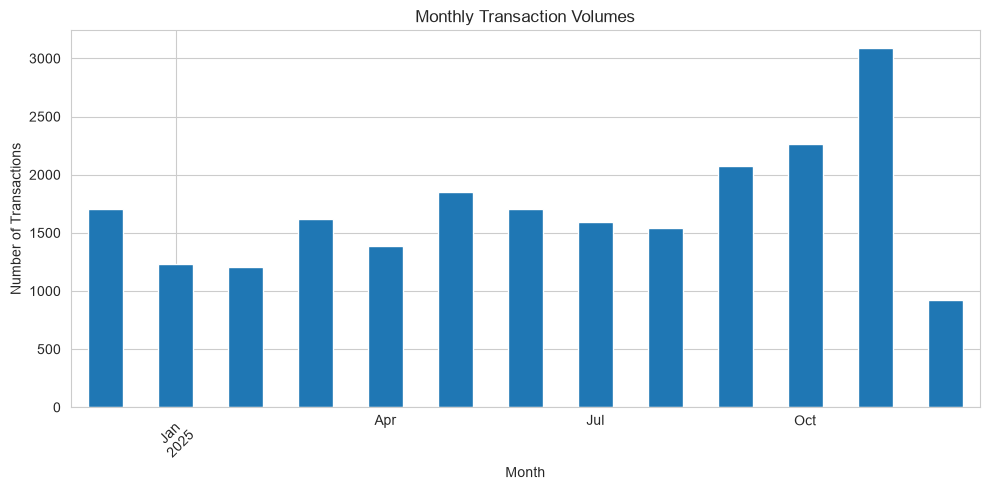

In [30]:
plt.figure(figsize=(10, 5))

monthly_transactions.plot(kind='bar')

plt.title('Monthly Transaction Volumes')
plt.xlabel('Month')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [31]:
# Calculate total monthly revenue
monthly_sales = df.groupby('InvoiceMonth')['Revenue'].sum().reset_index()

print(monthly_sales)

   InvoiceMonth       Revenue
0       2024-12  6.792367e+07
1       2025-01  5.582933e+07
2       2025-02  5.208536e+07
3       2025-03  7.137210e+07
4       2025-04  5.914003e+07
5       2025-05  7.434151e+07
6       2025-06  7.109639e+07
7       2025-07  7.040789e+07
8       2025-08  6.994326e+07
9       2025-09  1.036281e+08
10      2025-10  1.287425e+08
11      2025-11  1.677331e+08
12      2025-12  4.519251e+07


In [32]:
monthly_sales['InvoiceMonth'] = monthly_sales['InvoiceMonth'].astype(str)

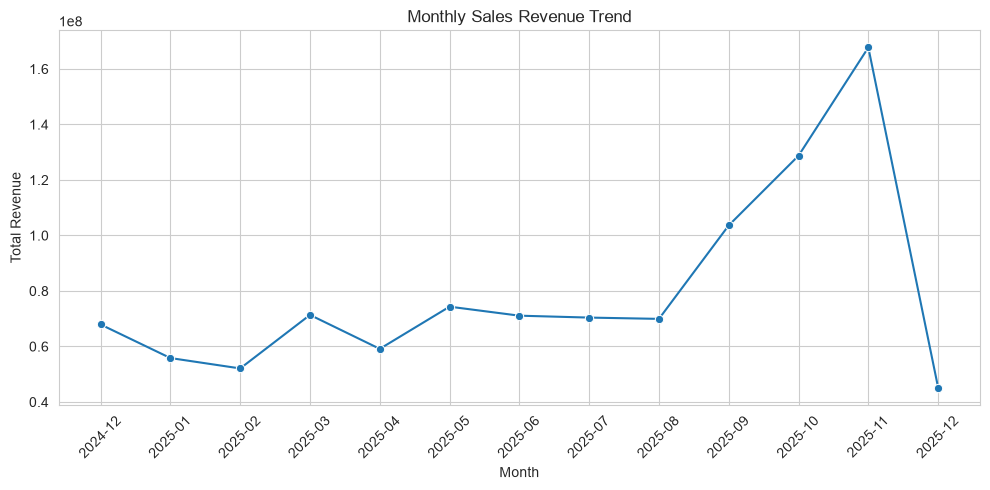

In [33]:
plt.figure(figsize=(10, 5))
sns.lineplot(x='InvoiceMonth', y='Revenue', data=monthly_sales, marker='o')
plt.title('Monthly Sales Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [34]:
# Calculate total spending for each customer
customer_spending = df.groupby('CustomerID')['Revenue'].sum()

# Display the top 10 highest-spending customers
top_customers = customer_spending.sort_values(ascending=False).head(10)

print(top_customers)

CustomerID
17841    20383830.65
14911    15362741.47
14096    12965429.74
12748    11912482.34
14606     7144512.92
15311     6301150.63
14646     5418075.66
13089     4739395.74
13263     4233075.52
14298     4123714.52
Name: Revenue, dtype: float64


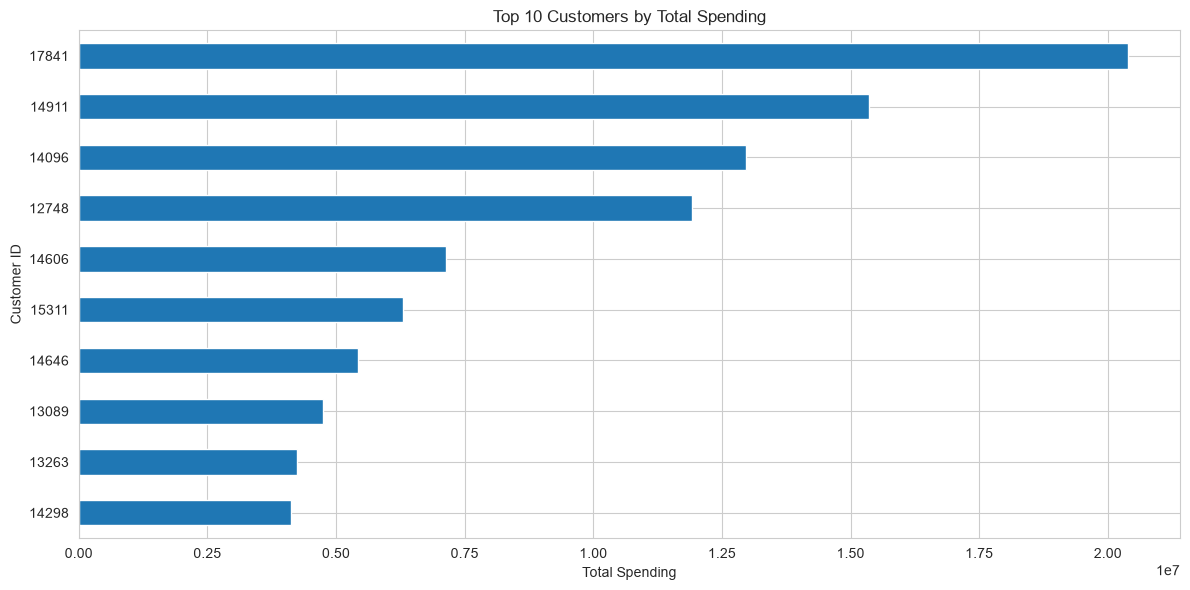

In [35]:
plt.figure(figsize=(12, 6))
top_customers.sort_values().plot(kind='barh')
plt.title('Top 10 Customers by Total Spending')
plt.xlabel('Total Spending')
plt.ylabel('Customer ID')
plt.tight_layout()
plt.show()

In [36]:
# Count the number of unique invoices for each customer
purchase_frequency = df.groupby('CustomerID')['InvoiceNo'].nunique()

# Calculate average purchase frequency
average_frequency = purchase_frequency.mean()

print("Average number of purchases per customer:", round(average_frequency, 2))

# Display the purchase frequency distribution
print(purchase_frequency.describe())

Average number of purchases per customer: 5.08
count    4372.000000
mean        5.075480
std         9.338754
min         1.000000
25%         1.000000
50%         3.000000
75%         5.000000
max       248.000000
Name: InvoiceNo, dtype: float64


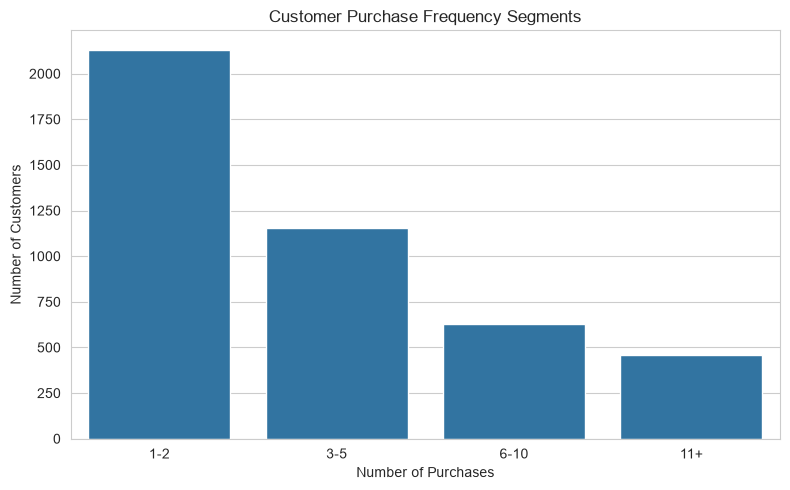

In [37]:
# Group customers by purchase frequency
purchase_groups = pd.cut(
    purchase_frequency,
    bins=[0, 2, 5, 10, float('inf')],
    labels=['1-2', '3-5', '6-10', '11+']
)

# Count customers in each group
frequency_counts = purchase_groups.value_counts().sort_index()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=frequency_counts.index,
    y=frequency_counts.values
)

plt.title('Customer Purchase Frequency Segments')
plt.xlabel('Number of Purchases')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

In [38]:
# Calculate revenue generated by each country
country_sales = df.groupby('Country')['Revenue'].sum().sort_values(
    ascending=False
)

# Display the top 10 countries
print(country_sales.head(10))

Country
Libya           37690362.35
Somalia         37663830.57
Togo            37592496.96
Mali            37508467.02
Ghana           37414593.40
Nigeria         37364243.60
Ethiopia        37228695.13
Mozambique      37145464.36
Sierra Leone    37140824.43
Algeria         37140683.52
Name: Revenue, dtype: float64


In [39]:
top_countries = df.groupby('Country')['CustomerID'].nunique().sort_values(ascending=False).head()

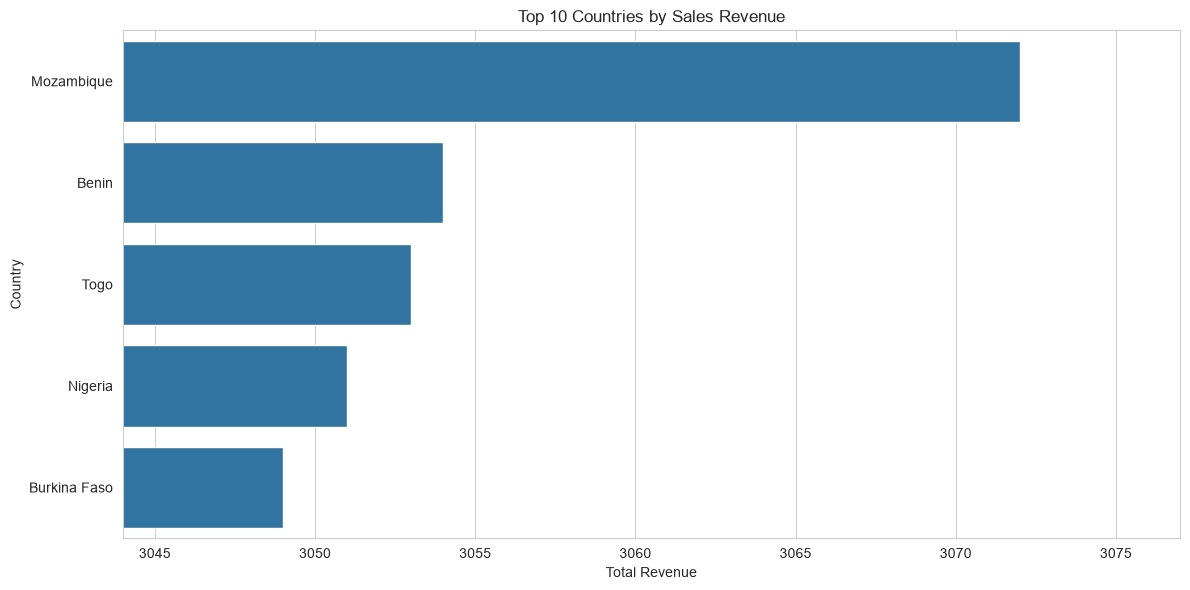

In [40]:
plt.figure(figsize=(12, 6))
sns.barplot(x=top_countries.values, y=top_countries.index)
plt.xlim(min(top_countries.values) - 5, max(top_countries.values) + 5)
plt.title('Top 10 Countries by Sales Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

In [41]:
# Combine customer numbers and revenue by country
country_analysis = df.groupby('Country').agg(
    Total_Customers=('CustomerID', 'nunique'),
    Total_Revenue=('Revenue', 'sum'),
    Total_Transactions=('InvoiceNo', 'nunique')
).sort_values(by='Total_Revenue', ascending=False)

# Display the results
country_analysis.head(10)

,Total_Customers,Total_Revenue,Total_Transactions
Country,,,
Libya,3030,37690362.35,8386
Somalia,3008,37663830.57,8411
Togo,3053,37592496.96,8327
Mali,3044,37508467.02,8237
Ghana,3035,37414593.40,8363
Nigeria,3051,37364243.60,8377
Ethiopia,3035,37228695.13,8323
Mozambique,3072,37145464.36,8377
Sierra Leone,3046,37140824.43,8419


In [42]:
print("Total transactions:", df['InvoiceNo'].nunique())

print("Total identified customers:",
      df['CustomerID'].nunique())

print("Total revenue:",
      round(df['Revenue'].sum(), 2))

print("Average purchase frequency:",
      round(purchase_frequency.mean(), 2))

print("Number of countries:",
      df['Country'].nunique())

print("Highest revenue month:",
      monthly_sales.idxmax())

print("Highest transaction month:",
      monthly_transactions.idxmax())
print("Top country by revenue:",
      country_sales.idxmax())

Total transactions: 22190
Total identified customers: 4372
Total revenue: 1037435721.11
Average purchase frequency: 5.08
Number of countries: 28
Highest revenue month: InvoiceMonth    12
Revenue         11
dtype: int64
Highest transaction month: 2025-11
Top country by revenue: Libya


In [43]:
df.head()

,InvoiceNo,InvoiceDate,CustomerID,StockCode,Description,Quantity,UnitPrice,Country,Revenue,InvoiceMonth
0,536365,2024-12-01 08:26:00,17850,SC1734,Electronics,65,10.23,Egypt,664.95,2024-12
1,536365,2024-12-01 08:26:00,17850,SC2088,Furniture,95,19.61,Mali,1862.95,2024-12
2,536365,2024-12-01 08:26:00,17850,SC3463,Books,78,61.49,Mali,4796.22,2024-12
3,536365,2024-12-01 08:26:00,17850,SC6228,Toys,15,24.73,South Africa,370.95,2024-12
4,536365,2024-12-01 08:26:00,17850,SC2149,Toys,50,38.83,Rwanda,1941.50,2024-12


In [44]:
cohort_data = df.groupby('CustomerID')['InvoiceMonth'].min()

In [45]:
cohort_data.name = 'CohortMonth'

In [46]:
cohort_data.head(10)

CustomerID
12346    2025-01
12347    2024-12
12348    2024-12
12349    2025-11
12350    2025-02
12352    2025-02
12353    2025-05
12354    2025-04
12355    2025-05
12356    2025-01
Name: CohortMonth, dtype: period[M]

In [47]:
df = df.merge(cohort_data, on='CustomerID')

In [48]:
df.head(10)

,InvoiceNo,InvoiceDate,CustomerID,StockCode,Description,Quantity,UnitPrice,Country,Revenue,InvoiceMonth,CohortMonth
0,536365,2024-12-01 08:26:00,17850,SC1734,Electronics,65,10.23,Egypt,664.95,2024-12,2024-12
1,536365,2024-12-01 08:26:00,17850,SC2088,Furniture,95,19.61,Mali,1862.95,2024-12,2024-12
2,536365,2024-12-01 08:26:00,17850,SC3463,Books,78,61.49,Mali,4796.22,2024-12,2024-12
3,536365,2024-12-01 08:26:00,17850,SC6228,Toys,15,24.73,South Africa,370.95,2024-12,2024-12
4,536365,2024-12-01 08:26:00,17850,SC2149,Toys,50,38.83,Rwanda,1941.50,2024-12,2024-12
5,536365,2024-12-01 08:26:00,17850,SC7895,Toys,41,45.31,Sierra Leone,1857.71,2024-12,2024-12
6,536365,2024-12-01 08:26:00,17850,SC8608,Books,44,39.31,Benin,1729.64,2024-12,2024-12
7,536366,2024-12-01 08:28:00,17850,SC3216,Toys,47,77.35,Burkina Faso,3635.45,2024-12,2024-12
8,536366,2024-12-01 08:28:00,17850,SC1236,Kitchenware,19,35.11,Nigeria,667.09,2024-12,2024-12
9,536367,2024-12-01 08:34:00,13047,SC4513,Furniture,55,3.21,Cote d'Ivoire,176.55,2024-12,2024-12


In [49]:
invoice_year, invoice_month = df['InvoiceMonth'].dt.year, df['InvoiceMonth'].dt.month
cohort_year, cohort_month = df['CohortMonth'].dt.year, df['CohortMonth'].dt.month

In [50]:
year_diff = invoice_year - cohort_year
month_diff = invoice_month - cohort_month

In [51]:
df['CohortIndex'] = year_diff * 12 + month_diff + 1
df.tail(10)

,InvoiceNo,InvoiceDate,CustomerID,StockCode,Description,Quantity,UnitPrice,Country,Revenue,InvoiceMonth,CohortMonth,CohortIndex
406819,581587,2025-12-09 12:50:00,12680,SC1744,Furniture,5,63.49,Nigeria,317.45,2025-12,2025-08,5
406820,581587,2025-12-09 12:50:00,12680,SC3155,Toys,28,17.31,Nigeria,484.68,2025-12,2025-08,5
406821,581587,2025-12-09 12:50:00,12680,SC2880,Electronics,41,78.23,Tunisia,3207.43,2025-12,2025-08,5
406822,581587,2025-12-09 12:50:00,12680,SC4436,Sports Equipment,58,39.06,Sudan,2265.48,2025-12,2025-08,5
406823,581587,2025-12-09 12:50:00,12680,SC9552,Furniture,74,5.99,Ethiopia,443.26,2025-12,2025-08,5
406824,581587,2025-12-09 12:50:00,12680,SC5440,Furniture,25,36.53,Mozambique,913.25,2025-12,2025-08,5
406825,581587,2025-12-09 12:50:00,12680,SC3576,Cloths,94,90.65,Tunisia,8521.10,2025-12,2025-08,5
406826,581587,2025-12-09 12:50:00,12680,SC5283,Furniture,14,40.07,Somalia,560.98,2025-12,2025-08,5
406827,581587,2025-12-09 12:50:00,12680,SC1099,Cosmetics,45,79.83,Senegal,3592.35,2025-12,2025-08,5
406828,581587,2025-12-09 12:50:00,12680,SC9276,Toys,6,46.62,Ethiopia,279.72,2025-12,2025-08,5


In [52]:
cohort_counts = df.groupby(['CohortMonth', 'CohortIndex'])['CustomerID'].nunique().reset_index()


In [55]:
cohort_pivot = cohort_counts.pivot(index='CohortMonth', columns='CohortIndex', values='CustomerID')

In [61]:
cohort_pivot

CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12,13
CohortMonth,,,,,,,,,,,,,
2024-12,948.0,362.0,317.0,367.0,341.0,376.0,360.0,336.0,336.0,374.0,354.0,474.0,260.0
2025-01,421.0,101.0,119.0,102.0,138.0,126.0,110.0,108.0,131.0,146.0,155.0,63.0,NaN
2025-02,380.0,94.0,73.0,106.0,102.0,94.0,97.0,107.0,98.0,119.0,35.0,NaN,NaN
2025-03,440.0,84.0,112.0,96.0,102.0,78.0,116.0,105.0,127.0,39.0,NaN,NaN,NaN
2025-04,299.0,68.0,66.0,63.0,62.0,71.0,69.0,78.0,25.0,NaN,NaN,NaN,NaN
2025-05,279.0,66.0,48.0,48.0,60.0,68.0,74.0,29.0,NaN,NaN,NaN,NaN,NaN
2025-06,235.0,49.0,44.0,64.0,58.0,79.0,24.0,NaN,NaN,NaN,NaN,NaN,NaN
2025-07,191.0,40.0,39.0,44.0,52.0,22.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-08,167.0,42.0,42.0,42.0,23.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [62]:
cohort_size = cohort_pivot.iloc[:, 0]
retention = cohort_pivot.divide(cohort_size, axis=0).round(3)
retention


CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12,13
CohortMonth,,,,,,,,,,,,,
2024-12,1.0,0.382,0.334,0.387,0.360,0.397,0.380,0.354,0.354,0.395,0.373,0.50,0.274
2025-01,1.0,0.240,0.283,0.242,0.328,0.299,0.261,0.257,0.311,0.347,0.368,0.15,NaN
2025-02,1.0,0.247,0.192,0.279,0.268,0.247,0.255,0.282,0.258,0.313,0.092,NaN,NaN
2025-03,1.0,0.191,0.255,0.218,0.232,0.177,0.264,0.239,0.289,0.089,NaN,NaN,NaN
2025-04,1.0,0.227,0.221,0.211,0.207,0.237,0.231,0.261,0.084,NaN,NaN,NaN,NaN
2025-05,1.0,0.237,0.172,0.172,0.215,0.244,0.265,0.104,NaN,NaN,NaN,NaN,NaN
2025-06,1.0,0.209,0.187,0.272,0.247,0.336,0.102,NaN,NaN,NaN,NaN,NaN,NaN
2025-07,1.0,0.209,0.204,0.230,0.272,0.115,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-08,1.0,0.251,0.251,0.251,0.138,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


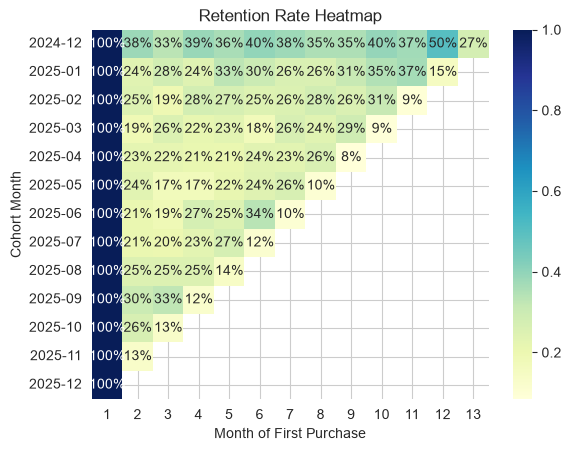

In [63]:
plt.Figure(figsize=(12,5))
sns.heatmap(retention, annot=True, fmt='.0%', cmap='YlGnBu')
plt.title('Retention Rate Heatmap')
plt.xlabel('Month of First Purchase')
plt.ylabel('Cohort Month')
plt.savefig('Rention_Heatmap.png')
plt.show()

In [64]:
# Count unique purchases made by each customer
customer_purchases = df.groupby(
    'CustomerID'
)['InvoiceNo'].nunique()

# Separate repeat customers from one-time customers
repeat_customers = customer_purchases[customer_purchases > 1]

one_time_customers = customer_purchases[customer_purchases == 1]

# Calculate the percentages
total_customers = len(customer_purchases)

repeat_percentage = (len(repeat_customers) / total_customers) * 100

one_time_percentage = (len(one_time_customers) / total_customers) * 100

print("Total customers:", total_customers)
print("Repeat customers:", len(repeat_customers))
print("One-time customers:", len(one_time_customers))

print("Repeat purchase rate:", round(repeat_percentage, 2), "%")
print("One-time customer rate:", round(one_time_percentage, 2), "%")

Total customers: 4372
Repeat customers: 3059
One-time customers: 1313
Repeat purchase rate: 69.97 %
One-time customer rate: 30.03 %


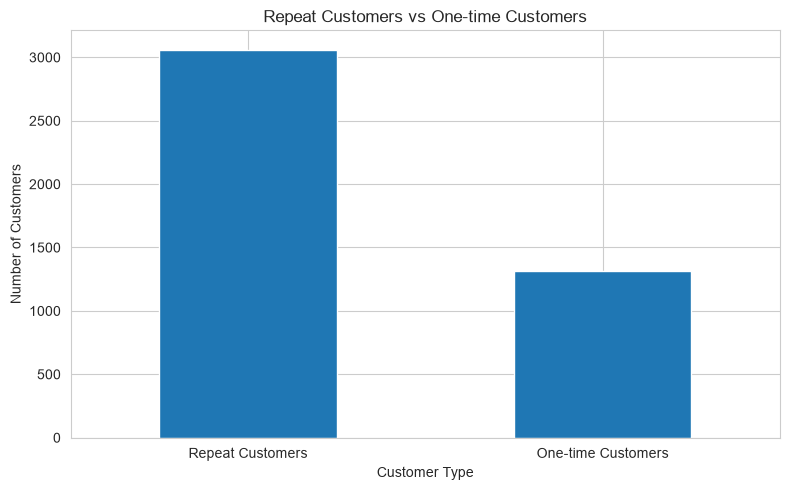

In [65]:
# Prepare the customer categories
purchase_categories = pd.Series({
    'Repeat Customers': len(repeat_customers),
    'One-time Customers': len(one_time_customers)
})

# Create a bar chart
plt.figure(figsize=(8, 5))

purchase_categories.plot(kind='bar')

plt.title('Repeat Customers vs One-time Customers')
plt.xlabel('Customer Type')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [69]:
# RFM Analysis
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)
reference_date

Timestamp('2025-12-10 12:50:00')

In [70]:
df.columns

Index(['InvoiceNo', 'InvoiceDate', 'CustomerID', 'StockCode', 'Description',
       'Quantity', 'UnitPrice', 'Country', 'Revenue', 'InvoiceMonth',
       'CohortMonth', 'CohortIndex'],
      dtype='str')

In [71]:
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,
    'InvoiceNo': pd.Series.nunique,
    'Revenue': 'sum'
}).reset_index()

In [72]:
rfm.columns = ('CustomerID', 'recency_days', 'frequency', 'monetary')
rfm.head()

,CustomerID,recency_days,frequency,monetary
0,12346,326,2,5342.40
1,12347,2,7,431501.00
2,12348,75,4,82378.47
3,12349,19,1,176075.12
4,12350,310,1,48173.37


In [73]:
x = rfm[['recency_days', 'frequency', 'monetary']].copy()

In [ ]:
from sklearn.preprocessing import StandardScaler

In [77]:
ss = StandardScaler()
x_scales = ss.fit_transform(x)

In [ ]:
x_scales[:5]

array([[ 2.32202285, -0.32936215, -0.39022789],
       [-0.89373323,  0.20610242,  0.32673724],
       [-0.1691956 , -0.11517632, -0.26062315],
       [-0.72500529, -0.43645506, -0.1029888 ],
       [ 2.16322008, -0.43645506, -0.31816948]])

In [66]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_style('whitegrid')

In [ ]:
! pip install yellowbrick

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [79]:
# Select the RFM variables
rfm_features = rfm[['recency_days', 'frequency', 'monetary']].copy()

# Reduce the effect of extreme values using log transformation
rfm_log = np.log1p(rfm_features)

# Standardise the variables
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

print("RFM data prepared for clustering.")

RFM data prepared for clustering.


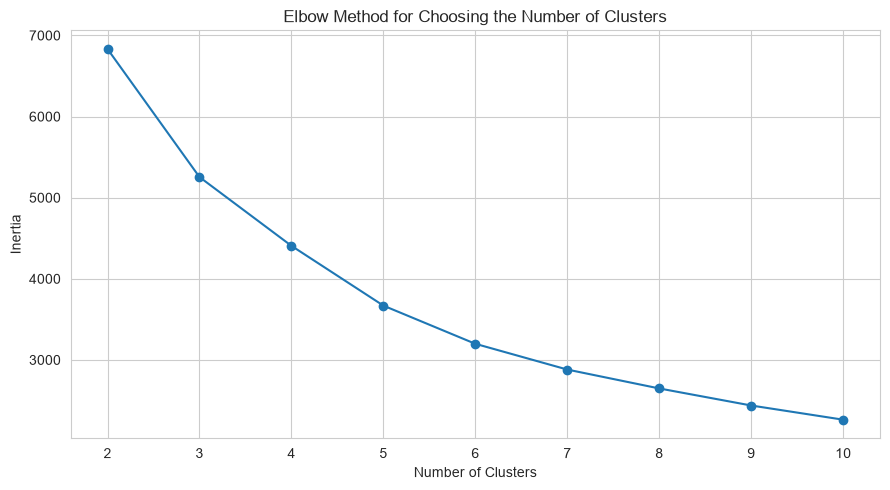

In [80]:
# Calculate inertia for different cluster numbers
inertia = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)

    inertia.append(kmeans.inertia_)


# Plot the Elbow Method
plt.figure(figsize=(9, 5))

plt.plot(
    range(2, 11),
    inertia,
    marker='o'
)

plt.title('Elbow Method for Choosing the Number of Clusters')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')

plt.xticks(range(2, 11))
plt.grid(True)

plt.tight_layout()
plt.show()

In [81]:
# Calculate silhouette scores for different clusters
for k in range(2, 7):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(rfm_scaled)

    score = silhouette_score(rfm_scaled, labels)

    print(
        f"Number of clusters: {k}, "
        f"Silhouette Score: {score:.3f}"
    )

Number of clusters: 2, Silhouette Score: 0.410
Number of clusters: 3, Silhouette Score: 0.310
Number of clusters: 4, Silhouette Score: 0.307
Number of clusters: 5, Silhouette Score: 0.286
Number of clusters: 6, Silhouette Score: 0.293


In [82]:
# Apply K-Means with four clusters
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Assign cluster labels
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

# Display the clustered customers
rfm.head(10)

,CustomerID,recency_days,frequency,monetary,Cluster
0,12346,326,2,5342.40,2
1,12347,2,7,431501.00,1
2,12348,75,4,82378.47,0
3,12349,19,1,176075.12,3
4,12350,310,1,48173.37,2
5,12352,36,11,241567.46,0
6,12353,204,1,4357.89,2
7,12354,232,1,161522.49,2
8,12355,214,1,37648.28,2
9,12356,23,3,161617.98,3


In [83]:
# Calculate average RFM values for each cluster
cluster_summary = rfm.groupby('Cluster').agg(
    Total_Customers=('recency_days', 'count'),
    Average_Recency=('recency_days', 'mean'),
    Average_Frequency=('frequency', 'mean'),
    Average_Monetary=('monetary', 'mean'),
    Total_Revenue=('monetary', 'sum')
).round(2)

print(cluster_summary)

         Total_Customers  Average_Recency  Average_Frequency  \
Cluster                                                        
0                   1155            74.42               4.77   
1                    786            10.82              15.71   
2                   1522           189.76               1.48   
3                    909            21.07               2.29   

         Average_Monetary  Total_Revenue  
Cluster                                   
0               250363.13   2.891694e+08  
1               750853.54   5.901709e+08  
2                46181.10   7.028763e+07  
3                96598.24   8.780780e+07  


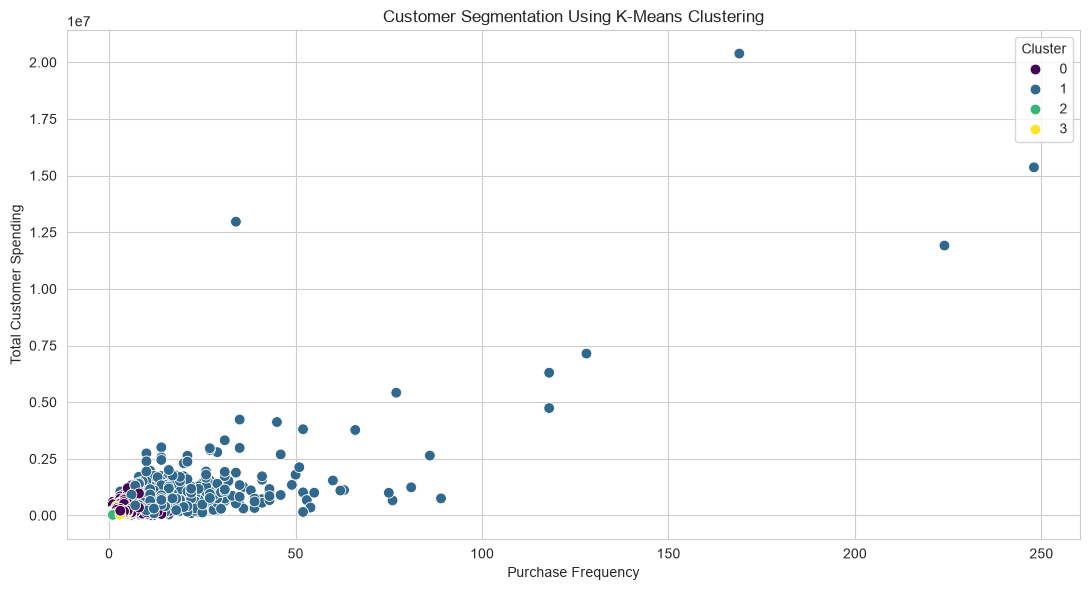

In [84]:
plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=rfm,
    x='frequency',
    y='monetary',
    hue='Cluster',
    palette='viridis',
    s=60
)

plt.title('Customer Segmentation Using K-Means Clustering')
plt.xlabel('Purchase Frequency')
plt.ylabel('Total Customer Spending')

plt.tight_layout()
plt.show()